# Notebook 7 — Does the population distinguish condition A from B?

**Summer course: data-analysis pitfalls**

Four sessions, 100 simultaneously recorded neurons each, 400 neurons in total.
Each session has 20 trials, 10 of condition A and 10 of condition B, in a random
order that was redrawn for every session. Pupil diameter was recorded on every
trial as well.

For each neuron we take its mean firing on A trials minus its mean firing on B
trials, and ask whether that difference is non-zero across the population.

> ### The claim
> *"The population distinguishes the two conditions: firing is higher on A trials
> than B trials (one-sample t-test across n = 400 neurons, t = 7.3, p = 2e-12).
> Two thirds of individual neurons show the effect."*

Run it and you'll get it.

**The claim is not supported by this analysis.** In the generative model behind
this dataset there is no condition term at all, and the A-vs-B difference is
exactly zero in expectation. Your job is to work out how a p-value of 2e-12
appeared anyway, and what the right analysis would have been.

`hints.md` has guiding questions and `notebook7_solution.ipynb` has the answer.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

plt.rcParams['font.family']       = 'Arial'
plt.rcParams['font.sans-serif']   = ['Arial', 'DejaVu Sans']
plt.rcParams['axes.spines.top']   = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['pdf.fonttype']      = 42
plt.rcParams['ps.fonttype']       = 42

SESSION_COLORS = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']


In [2]:
d = np.load('data/data.npz')
activity       = d['activity']         # (sessions, neurons, trials) firing rate, spikes/s
condition      = d['condition']        # (sessions, trials)  +1 = A, -1 = B
pupil_diameter = d['pupil_diameter']   # (sessions, trials)  recorded alongside, z-scored
n_sessions, n_neurons, n_trials = activity.shape
print(f'{n_sessions} sessions x {n_neurons} neurons = {n_sessions*n_neurons} neurons, '
      f'{n_trials} trials per session')
print(f'A/B labels were shuffled per session, e.g. session 0: {condition[0]}')
print(f'pupil diameter was also recorded on every trial')


4 sessions x 100 neurons = 400 neurons, 20 trials per session
A/B labels were shuffled per session, e.g. session 0: [ 1  1 -1 -1 -1  1  1 -1  1  1  1  1 -1  1 -1  1 -1 -1 -1 -1]
pupil diameter was also recorded on every trial


## Step 1 — Look at the data first

The whole dataset is small enough to simply look at: neurons down, trials across,
one panel per session.


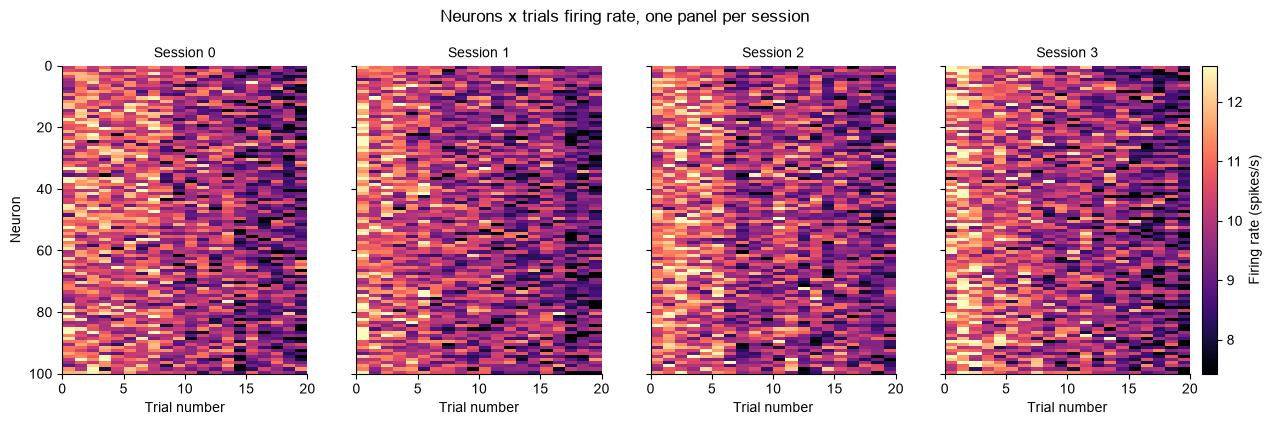

In [3]:
vmin, vmax = np.percentile(activity, [2, 98])

fig, axes = plt.subplots(1, n_sessions, figsize=(15, 4.0), sharey=True)
for s in range(n_sessions):
    im = axes[s].imshow(activity[s], aspect='auto', cmap='magma',
                        vmin=vmin, vmax=vmax, interpolation='nearest',
                        extent=[0, n_trials, n_neurons, 0])
    axes[s].set_xlabel('Trial number')
    axes[s].set_title(f'Session {s}', fontsize=10)
axes[0].set_ylabel('Neuron')
cb = fig.colorbar(im, ax=axes, fraction=0.02, pad=0.01)
cb.set_label('Firing rate (spikes/s)')
fig.suptitle('Neurons x trials firing rate, one panel per session', y=1.02)
plt.show()


And the population average on each trial, session by session.


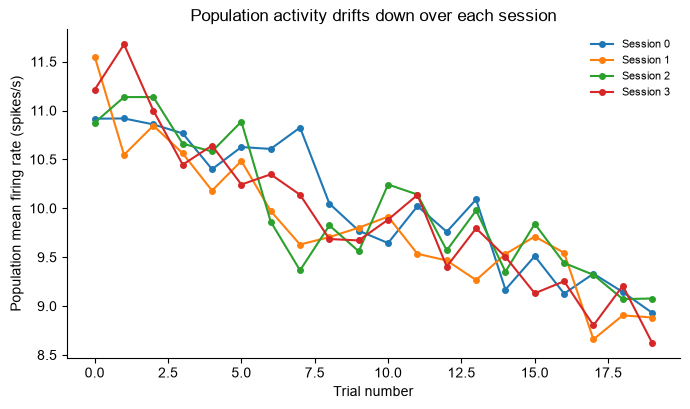

In [4]:
fig, ax = plt.subplots(figsize=(7.0, 4.2))
for s in range(n_sessions):
    ax.plot(np.arange(n_trials), activity[s].mean(0), 'o-', ms=4,
            color=SESSION_COLORS[s], label=f'Session {s}')
ax.set_xlabel('Trial number')
ax.set_ylabel('Population mean firing rate (spikes/s)')
ax.set_title('Population activity drifts down over each session')
ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()


## Step 2 — Test A vs B across all neurons


mean A - B = +0.188 spikes/s across 400 neurons
neurons with A > B: 66.2%
one-sample t-test: t = 7.30, p = 1.52e-12


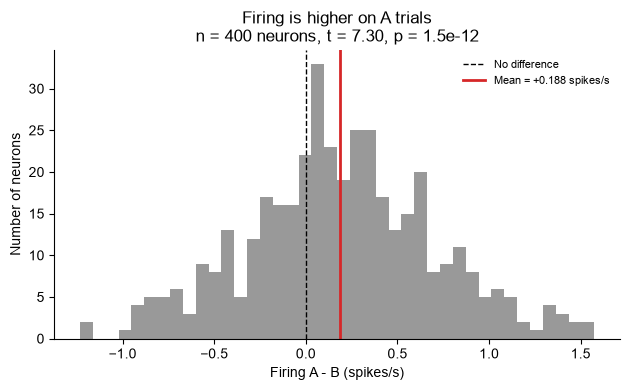

In [5]:
# Per-neuron mean firing on A trials minus mean firing on B trials.
# The A/B labels are shuffled independently in each session, so index per session.
AmB = np.zeros((n_sessions, n_neurons))
for s in range(n_sessions):
    AmB[s] = (activity[s][:, condition[s] == 1].mean(1)
              - activity[s][:, condition[s] == -1].mean(1))

flat = AmB.ravel()
t, p = stats.ttest_1samp(flat, 0.0)
print(f'mean A - B = {flat.mean():+.3f} spikes/s across {flat.size} neurons')
print(f'neurons with A > B: {np.mean(flat > 0)*100:.1f}%')
print(f'one-sample t-test: t = {t:.2f}, p = {p:.2e}')

fig, ax = plt.subplots(figsize=(6.4, 4.0))
ax.hist(flat, bins=40, color='0.6')
ax.axvline(0.0, color='k', ls='--', lw=1.0, label='No difference')
ax.axvline(flat.mean(), color='tab:red', lw=2,
           label=f'Mean = {flat.mean():+.3f} spikes/s')
ax.set_xlabel('Firing A - B (spikes/s)')
ax.set_ylabel('Number of neurons')
ax.set_title(f'Firing is higher on A trials\n'
             f'n = {flat.size} neurons, t = {t:.2f}, p = {p:.1e}')
ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()


Two thirds of 400 neurons fire more on A than on B, the population mean is
clearly positive, and p = 2e-12.

Nothing in the generative model responds to the condition. **Where did this come
from, and what should have been done instead?**
